## 1. Exploración del dataset
En esta sección cargaremos el dataset de tweets sobre Inteligencia Artificial, revisaremos su estructura general, tipos de datos, la presencia de valores faltantes y analizaremos el comportamiento de la variable objetivo (`polarity`).

Importación de Librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo gráfico predeterminado de Seaborn
sns.set(style="whitegrid")
%matplotlib inline

Carga del dataset de Tweets

In [ ]:
# Carga el dataset de Tweets
df = pd.read_csv("https://raw.githubusercontent.com/Barlita03/TP-CienciasDeDatos/main/Consigna/ia_tweets.csv")
# df = pd.read_csv("https://drive.google.com/uc?id=1kYip8Kzlvh4WJ9rrC29R3eYVbOj8XCJQ")

# Muestra las primeras filas del dataset
df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


Información básica del dataset

In [ ]:
# Información general (filas, columnas, tipos de datos y no nulos)
df.info()

# Verifica explícitamente la cantidad de valores faltantes por columna
print("\nValores faltantes por columna:")
print(df.isnull().sum())

# Revisa tipos de datos detallados
print("\nTipos de datos:")
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 4038 entries, 0 to 4037
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   ID                         4038 non-null   int64
 1   text                       4038 non-null   str  
 2   polarity                   4038 non-null   str  
 3   favorite_count             4038 non-null   int64
 4   retweet_count              4038 non-null   int64
 5   user_followers_count       4038 non-null   int64
 6   user_friends_count         4038 non-null   int64
 7   user_favourites_count      4038 non-null   int64
 8   user_statuses_count        4038 non-null   int64
 9   user_verified              4038 non-null   int64
 10  user_has_extended_profile  4038 non-null   int64
 11  user_is_translator         4038 non-null   int64
 12  user_protected             4038 non-null   int64
 13  user_default_profile       4038 non-null   int64
dtypes: int64(12), str(2)
memory usage: 

*Observación: El dataset cuenta con 4038 registros y 14 columnas. El análisis de valores nulos (isnull().sum()) confirma que no existen valores faltantes en ninguna de las variables, por lo que no es necesario aplicar ninguna estrategia de limpieza de datos en esta etapa.*

Análisis de la columna "polarity"


Cantidad de tweets por clase:
polarity
NEU    2689
P       757
N       592
Name: count, dtype: int64

Porcentaje por clase:
polarity
NEU    66.592372
P      18.746904
N      14.660723
Name: proportion, dtype: float64


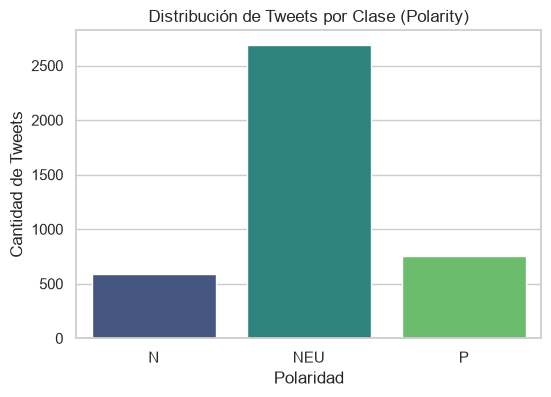

In [ ]:
# Conteo de registros por clase en polarity
conteo_clases = df['polarity'].value_counts()
print("Cantidad de tweets por clase:")
print(conteo_clases)

# Porcentajes de participación por clase
porcentaje_clases = df['polarity'].value_counts(normalize=True) * 100
print("\nPorcentaje por clase:")
print(porcentaje_clases)

# Gráfico de barras (countplot) para visualizar la distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(x='polarity', hue='polarity', data=df, palette='viridis', legend=False)
plt.title('Distribución de Tweets por Clase (Polarity)')
plt.xlabel('Polaridad')
plt.ylabel('Cantidad de Tweets')
plt.show()

***Observación:***

**Cantidad de tweets por clase:**
  * **NEU (Neutral):** 2689 tweets (66.59%)
  * **P (Positivo):** 757 tweets (18.75%)
  * **N (Negativo):** 592 tweets (14.66%)

**¿El dataset está balanceado?**
  No, el dataset presenta un **marcado desbalance de clases**. La clase neutral (`NEU`) representa casi dos tercios del total de los datos (66.59%), mientras que las clases positiva y negativa minoritarias suman en conjunto poco más del 33%.

**¿Cómo puede afectar esto al entrenamiento de modelos?**
  El marcado desbalance de clases impacta de forma directa en el proceso de entrenamiento de los algoritmos de Machine Learning. Dado que la mayoría de los clasificadores buscan optimizar métricas globales de rendimiento (como el *accuracy*), un desproporcionado volumen de la clase mayoritaria (`NEU`) puede provocar que el modelo se sesgue o ignore los patrones de las clases minoritarias (`P` y `N`). Como se advierte ante la *Accuracy Paradox*, un modelo podría alcanzar una alta exactitud aparente simplemente prediciendo de manera sistemática la clase más frecuente, volviéndose inútil para la tarea de detección de sentimiento.

## 2. Análisis de las variables disponibles

En esta sección analizamos las métricas de interacción del dataset. Empezamos por los likes (`favorite_count`): cómo se distribuyen, si tienen outliers y si cambian según el sentimiento del tweet.

### 2.1 Likes (`favorite_count`)

#### Distribución de los likes

count    4038.000000
mean        3.815998
std        45.041517
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max      2243.000000
Name: favorite_count, dtype: float64

Tweets con 0 likes: 53.15%

Percentiles:
0.50     0.0
0.75     1.0
0.90     5.0
0.95    10.0
0.99    41.0
Name: favorite_count, dtype: float64


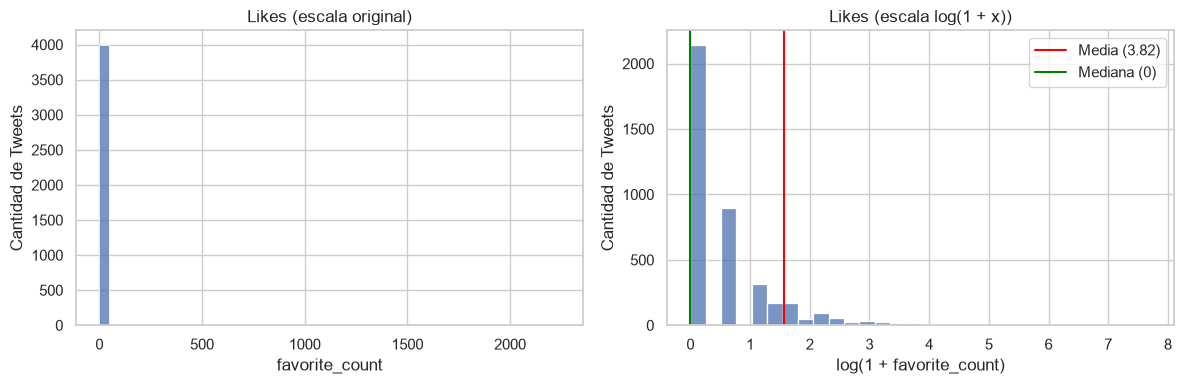

In [ ]:
# Estadísticas descriptivas de los likes
print(df['favorite_count'].describe())

# Porcentaje de tweets sin ningún like
print(f"\nTweets con 0 likes: {(df['favorite_count'] == 0).mean() * 100:.2f}%")

# Percentiles altos, para ver dónde se concentran los valores grandes
print("\nPercentiles:")
print(df['favorite_count'].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

# Histograma en escala original y en escala logarítmica (log(1 + x), porque hay muchos ceros)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['favorite_count'], bins=50, ax=axes[0])
axes[0].set_title('Likes (escala original)')
axes[0].set_xlabel('favorite_count')
axes[0].set_ylabel('Cantidad de Tweets')
sns.histplot(np.log1p(df['favorite_count']), bins=30, ax=axes[1])
# Media y mediana, llevadas a la misma escala que el histograma
media_likes = df['favorite_count'].mean()
mediana_likes = df['favorite_count'].median()
axes[1].axvline(np.log1p(media_likes), color='red', label=f'Media ({media_likes:.2f})')
axes[1].axvline(np.log1p(mediana_likes), color='green', label=f'Mediana ({mediana_likes:.0f})')
axes[1].legend()
axes[1].set_title('Likes (escala log(1 + x))')
axes[1].set_xlabel('log(1 + favorite_count)')
axes[1].set_ylabel('Cantidad de Tweets')
plt.tight_layout()
plt.show()

***Análisis:***

La distribución está muy sesgada.
- Más de la mitad (53,15%) de los tweets no tienen likes.
- El 99% de los tweets tiene 41 likes o menos y el 95% menos de 10.

En el histograma orginal hubo que hacer un escalado, por el outlier de 2243 likes. Para eso se uso la escala `log(1 + x)` que comprime los grandes valores.

Las líneas muestran que la media (3.82 likes) queda lejos de la mediana (0): unos pocos tweets con muchísimos likes tiran la media hacia arriba. Por eso, para describir a un tweet típico, la mediana es más representativa que la media.

#### Outliers

Q1 = 0.0, Q3 = 1.0, IQR = 1.0, límite superior = 2.5
Outliers según IQR: 678 tweets (16.79%)

Tweets con más likes:
      favorite_count  retweet_count  user_followers_count polarity
1292            2243            502                146283        P
3921            1061            122                   530      NEU
993             1033            111                283630      NEU
1886             495            146                 19737      NEU
2188             396            170                 72127      NEU


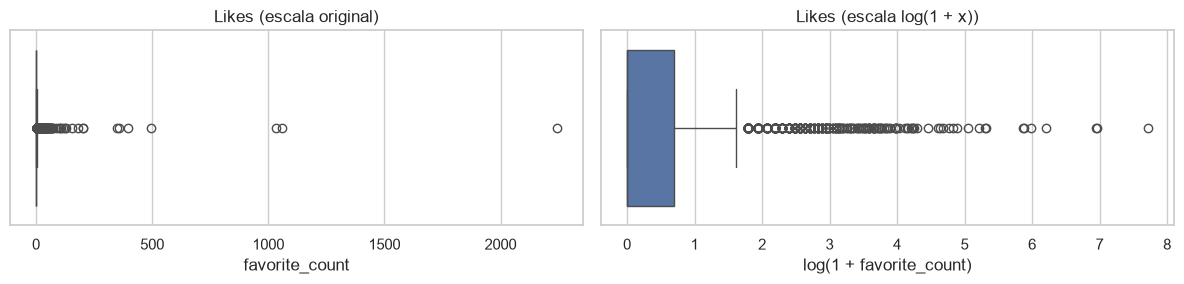

In [ ]:
# Criterio IQR: es outlier todo valor mayor a Q3 + 1.5 * IQR
q1 = df['favorite_count'].quantile(0.25)
q3 = df['favorite_count'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
outliers = df[df['favorite_count'] > limite_superior]
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}, límite superior = {limite_superior}")
print(f"Outliers según IQR: {len(outliers)} tweets ({len(outliers) / len(df) * 100:.2f}%)")

# Los 5 tweets con más likes
print("\nTweets con más likes:")
print(df.nlargest(5, 'favorite_count')[['favorite_count', 'retweet_count', 'user_followers_count', 'polarity']])

# Boxplot en escala original y en escala logarítmica
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=df['favorite_count'], ax=axes[0])
axes[0].set_title('Likes (escala original)')
sns.boxplot(x=np.log1p(df['favorite_count']), ax=axes[1])
axes[1].set_title('Likes (escala log(1 + x))')
axes[1].set_xlabel('log(1 + favorite_count)')
plt.tight_layout()
plt.show()

***Análisis:***

El criterio IQR marca como outlier a todo tweet con más de 2.5 likes. Como Q1 = 0 y Q3 = 1, el rango intercuartil es de apenas 1 like, y el criterio termina considerando outliers a 678 tweets (16.79% del dataset), es decir, a cualquier tweet con 3 likes o más.

Esto muestra que **el criterio IQR no sirve para esta variable**. No se trata de valores raros ni de errores de carga: en redes sociales es normal que casi todos los tweets tengan pocos likes y unos pocos tengan muchísimos. Es por eso que no eliminamos estos valores.

#### Likes según el sentimiento

             media  mediana  maximo  porcentaje_con_likes
polarity                                                 
N         2.967905      0.0     350             43.750000
NEU       3.663816      0.0    1061             47.861659
P         5.019815      0.0    2243             45.706737

Media por clase sin el tweet con más likes (2243 likes):
polarity
N      2.967905
NEU    3.663816
P      2.059524
Name: favorite_count, dtype: float64


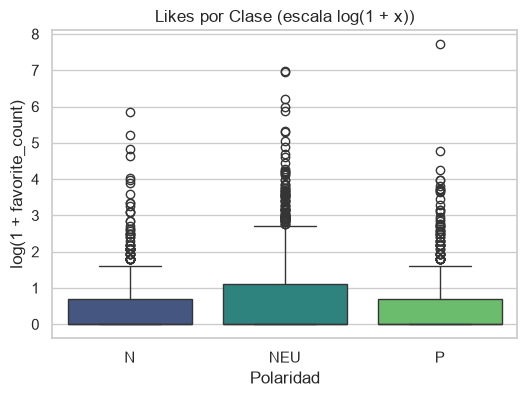

In [ ]:
# Media, mediana, máximo y porcentaje de tweets con al menos un like, por clase
resumen_likes = df.groupby('polarity')['favorite_count'].agg(
    media='mean',
    mediana='median',
    maximo='max',
    porcentaje_con_likes=lambda s: (s > 0).mean() * 100
)
print(resumen_likes)

# Media por clase sin el tweet con más likes, para ver cuánto pesa un solo valor extremo
df_sin_maximo = df[df['favorite_count'] < df['favorite_count'].max()]
print(f"\nMedia por clase sin el tweet con más likes ({df['favorite_count'].max()} likes):")
print(df_sin_maximo.groupby('polarity')['favorite_count'].mean())

# Boxplot de los likes por clase, en escala logarítmica
plt.figure(figsize=(6, 4))
sns.boxplot(x='polarity', y=np.log1p(df['favorite_count']), hue='polarity', data=df, palette='viridis', legend=False)
plt.title('Likes por Clase (escala log(1 + x))')
plt.xlabel('Polaridad')
plt.ylabel('log(1 + favorite_count)')
plt.show()

***Análisis:***

**¿Los tweets positivos reciben más interacción que los negativos?**

A primera vista parece que sí: los tweets positivos tienen una media de 5.02 likes, contra 2.97 de los negativos. Pero esa diferencia se explica por un solo tweet positivo con 2243 likes. Al quitar únicamente ese tweet, la media de los positivos baja a 2.06 y queda por debajo de los negativos (2.97) y de los neutrales (3.66).

El resto de los indicadores también muestran clases muy parecidas: la mediana es 0 en las tres, el porcentaje de tweets con al menos un like va de 43.75% (N) a 47.86% (NEU), y en el boxplot las cajas de N y P son iguales y la de NEU es apenas más alta.

Por lo tanto, **no encontramos una diferencia clara en la cantidad de likes según el sentimiento**. La diferencia que muestra la media sale de un único valor extremo, y por eso en esta variable conviene mirar la mediana y la escala logarítmica antes que la media.

#### Relación con la cantidad de seguidores

Correlación entre likes y seguidores (valores originales): 0.04


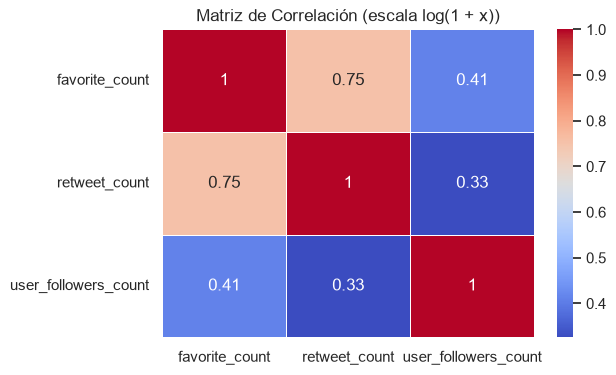

In [ ]:
# Correlación entre likes, retweets y seguidores del usuario
columnas_interaccion = ['favorite_count', 'retweet_count', 'user_followers_count']

# Con los valores originales, unos pocos valores extremos dominan la correlación
print("Correlación entre likes y seguidores (valores originales): "
      f"{df['favorite_count'].corr(df['user_followers_count']):.2f}")

# Por eso calculamos la correlación sobre los valores en escala log(1 + x)
plt.figure(figsize=(6, 4))
sns.heatmap(np.log1p(df[columnas_interaccion]).corr(), annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Matriz de Correlación (escala log(1 + x))')
plt.show()

***Análisis:***

Con los valores originales, la correlación entre likes y seguidores es casi nula (0.04), porque unos pocos tweets con valores enormes dominan el cálculo. En escala logarítmica aparece una correlación positiva moderada (0.41): las cuentas con más seguidores tienden a recibir más likes. Esto sugiere que los likes dependen más de **quién publica** el tweet que del sentimiento de lo que dice.

Los likes también tienen una correlación alta con los retweets (0.75): los tweets que gustan también se comparten. Es esperable, porque las dos métricas miden la misma idea de interacción.

#### Conclusión sobre los likes

- La variable está muy sesgada: la mayoría de los tweets tiene 0 o 1 like y unos pocos tienen cientos o miles.
- Los valores extremos son reales, así que no los eliminamos. Para analizarlos usamos la escala `log(1 + x)`, ya que el criterio IQR no sirve con esta distribución.
- No se observa una diferencia clara de likes entre tweets positivos, negativos y neutrales.
- Los likes se relacionan más con la cantidad de seguidores del usuario que con el sentimiento.

Con esto, los likes parecen una feature **débil** para predecir la polaridad.